# setup + imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

In [3]:
train_data = pd.read_csv('train_data.csv')
test_data = pd.read_csv('test_data.csv')

In [4]:
train1 = train_data.loc[train_data['subtaskID']==1]
train2 = train_data.loc[train_data['subtaskID']==2]
train3 = train_data.loc[train_data['subtaskID']==3]

# data exploration

In [5]:
print(train_data['subtaskID'].value_counts())
print(test_data['subtaskID'].value_counts())

subtaskID
3    5000
2    1000
1     100
Name: count, dtype: int64
subtaskID
1    5000
2    5000
3    5000
Name: count, dtype: int64


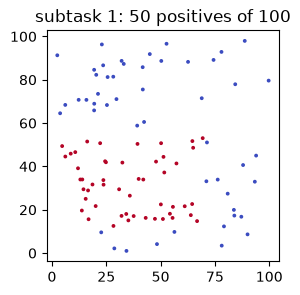

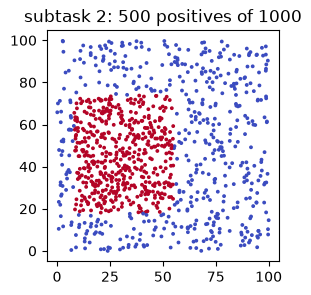

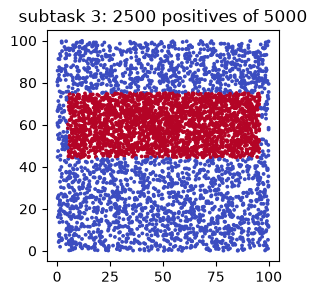

In [6]:
for sid in [1, 2, 3]:
  part = train_data[train_data['subtaskID'] == sid]
  plt.figure(figsize=(3, 3))
  plt.scatter(part['X'], part['Y'], c=part['answer'], s=3, cmap = 'coolwarm')
  plt.title(f'subtask {sid}: {int(part["answer"].sum())} positives of {len(part)}')
  plt.show()

# validare

In [7]:
def evaluate(model, X, y):
    kf = StratifiedKFold(n_splits=5, random_state=0, shuffle=True)

    scores = []
    for fit_rows, val_rows in kf.split(X, y):
        X_fit = X.iloc[fit_rows]
        y_fit = y.iloc[fit_rows]
        X_val = X.iloc[val_rows]
        y_val = y.iloc[val_rows]

        model.fit(X_fit, y_fit)
        preds = model.predict(X_val)
        score = accuracy_score(y_val, preds)
        scores.append(score)

    return np.mean(scores)

# model

In [8]:
class Rectangle:
    def fit(self, data, y):
        unu = data[y==1]
        if (len(unu)==0):
            self.x1 = self.x2 = self.y1 = self.y2 = -1
            return self
        self.x1 = unu['X'].min()
        self.x2 = unu['X'].max()
        self.y1 = unu['Y'].min()
        self.y2 = unu['Y'].max()
        return self
    def predict(self, data):
        inside = (data['X'] >= self.x1) & (data['X'] <= self.x2) & (data['Y'] >= self.y1) & (data['Y'] <= self.y2)
        return [1 if punct else 0 for punct in inside]

In [9]:
class BalancedBox(Rectangle):
    def fit(self, data, y):
        super().fit(data, y)                    
        self.share = y.mean()                    
        if self.x1 == -1:
            return self
        neg = data[y == 0]
        tx1, tx2, ty1, ty2 = self.x1, self.x2, self.y1, self.y2

        band = neg[(neg['Y'] >= ty1) & (neg['Y'] <= ty2)]
        left = band[band['X'] < tx1]['X']
        right = band[band['X'] > tx2]['X']
        self.ox1 = left.max() if len(left) > 0 else 0
        self.ox2 = right.min() if len(right) > 0 else 100
        band = neg[(neg['X'] >= tx1) & (neg['X'] <= tx2)]
        below = band[band['Y'] < ty1]['Y']
        above = band[band['Y'] > ty2]['Y']
        self.oy1 = below.max() if len(below) > 0 else 0
        self.oy2 = above.min() if len(above) > 0 else 100
        return self

    def box(self, t):                            
        return (self.x1 - t * (self.x1 - self.ox1), self.x2 + t * (self.ox2 - self.x2),
                self.y1 - t * (self.y1 - self.oy1), self.y2 + t * (self.oy2 - self.y2))

    def predict(self, data):
        if self.x1 == -1:
            return np.zeros(len(data), dtype=int)
        best_t, best_gap = 0, None
        for t in np.linspace(0, 0.99, 100):      
            x1, x2, y1, y2 = self.box(t)
            inside = (data['X'] >= x1) & (data['X'] <= x2) & (data['Y'] >= y1) & (data['Y'] <= y2)
            gap = abs(inside.mean() - self.share)
            if best_gap is None or gap < best_gap:
                best_t, best_gap = t, gap
        self.t = best_t                          
        x1, x2, y1, y2 = self.box(best_t)
        inside = (data['X'] >= x1) & (data['X'] <= x2) & (data['Y'] >= y1) & (data['Y'] <= y2)
        return inside.astype(int).values

In [10]:
for sid in [1, 2, 3]:
  part = train_data[train_data['subtaskID'] == sid]
  X = part[['X', 'Y']]
  y = part['answer']
  print('subtask', sid, evaluate(BalancedBox(), X, y))

subtask 1 1.0
subtask 2 1.0
subtask 3 1.0


# submisie

In [11]:
answers = []
for sid in[1, 2, 3]:
    part = train_data[train_data['subtaskID'] == sid]
    test_part = test_data[test_data['subtaskID'] == sid]
    model = BalancedBox().fit(part[['X', 'Y']], part['answer'])
    preds = model.predict(test_part[['X', 'Y']])
    rez = pd.DataFrame({
        'datapointID': test_part['datapointID'],
        'answer': preds,
        'subtaskID': sid
    })
    answers.append(rez)

submission = pd.concat(answers, ignore_index=True)
submission.to_csv('output.csv', index=False)